# 03 · Exploratory Data Analysis
All figures are produced by `src/eda.py`. The headline numbers are in `reports/key_metrics.json`.

In [1]:
import sys, json
from pathlib import Path
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [2]:
K = json.load(open(ROOT / "reports/key_metrics.json"))
print(f"Total income  ₹{K['total_income']/1e7:.2f} Cr | expenses ₹{K['total_expenses']/1e7:.2f} Cr | savings rate {K['portfolio_savings_rate']:.1%}")
print(f"Lowest-saving month {K['worst_month']} ({K['worst_month_savings_rate']:.1%}); highest {K['best_month']} ({K['best_month_savings_rate']:.1%})")

Total income  ₹13.18 Cr | expenses ₹10.67 Cr | savings rate 19.0%
Lowest-saving month 2024-12 (12.4%); highest 2025-02 (27.3%)


## 1. Monthly income, expenses and savings

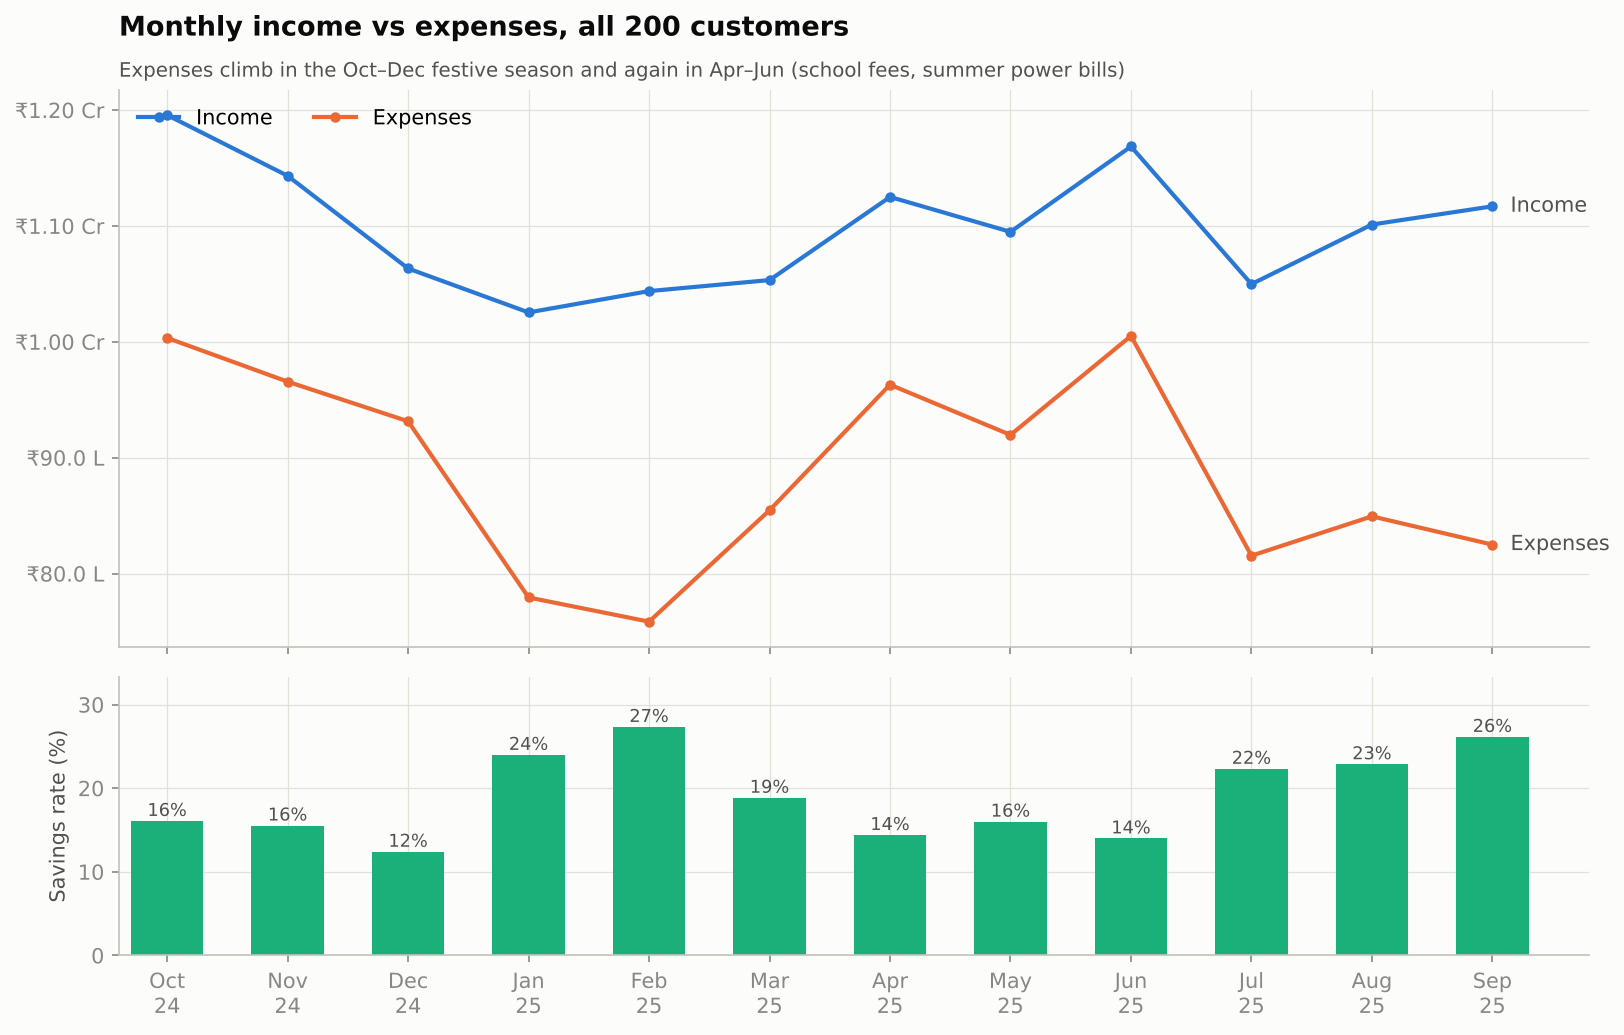

,year_month,income,expenses,net_cash_flow,investment,borrowing,savings_rate
0,2024-10,"11,956,637.00","10,033,552.71","1,923,084.29","600,300.00","28,000.00",0.16
1,2024-11,"11,432,556.00","9,656,102.99","1,776,453.01","600,300.00","48,000.00",0.16
2,2024-12,"10,632,685.82","9,314,252.41","1,318,433.41","600,300.00","165,000.00",0.12
3,2025-01,"10,253,603.00","7,793,887.79","2,459,715.21","600,300.00","142,000.00",0.24
4,2025-02,"10,437,639.00","7,585,065.94","2,852,573.06","600,300.00","46,000.00",0.27
5,2025-03,"10,532,693.57","8,546,224.41","1,986,469.16","600,300.00","35,000.00",0.19
6,2025-04,"11,250,085.00","9,629,891.44","1,620,193.56","600,300.00","91,000.00",0.14
7,2025-05,"10,948,844.00","9,196,688.60","1,752,155.40","595,000.00","97,000.00",0.16
8,2025-06,"11,685,609.68","10,050,623.17","1,634,986.51","595,000.00","172,000.00",0.14
9,2025-07,"10,497,752.00","8,154,426.12","2,343,325.88","586,000.00","70,000.00",0.22


In [3]:
display(Image(ROOT / "reports/figures/01_monthly_cashflow.png", width=900))
pd.read_csv(ROOT / "reports/eda_tables/portfolio_monthly.csv")

## 2. Spending by category & spend type

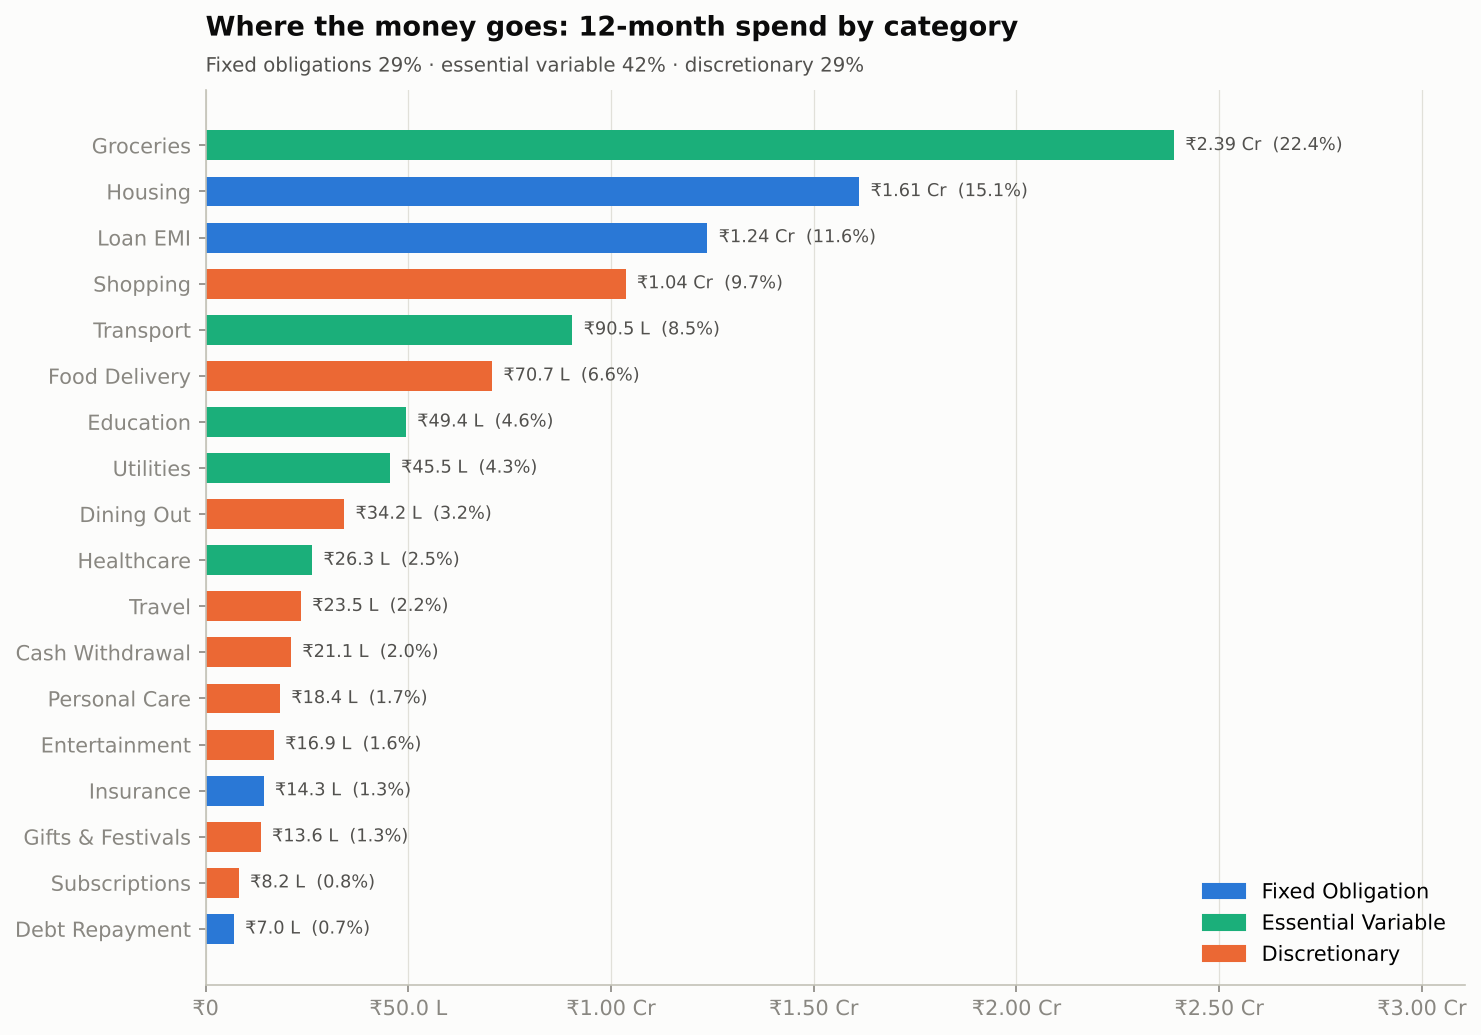

,category,spend_type,amount,share
0,Groceries,Essential Variable,"23,887,708.32",0.22
1,Housing,Fixed Obligation,"16,124,400.00",0.15
2,Loan EMI,Fixed Obligation,"12,378,144.00",0.12
3,Shopping,Discretionary,"10,361,357.70",0.10
4,Transport,Essential Variable,"9,048,118.69",0.08
5,Food Delivery,Discretionary,"7,068,455.99",0.07
6,Education,Essential Variable,"4,942,398.38",0.05
7,Utilities,Essential Variable,"4,545,176.70",0.04
8,Dining Out,Discretionary,"3,421,071.64",0.03
9,Healthcare,Essential Variable,"2,629,935.61",0.02


In [4]:
display(Image(ROOT / "reports/figures/02_spend_by_category.png", width=850))
pd.read_csv(ROOT / "reports/eda_tables/spend_by_category.csv").head(10)

## 3. Spending trends and seasonality

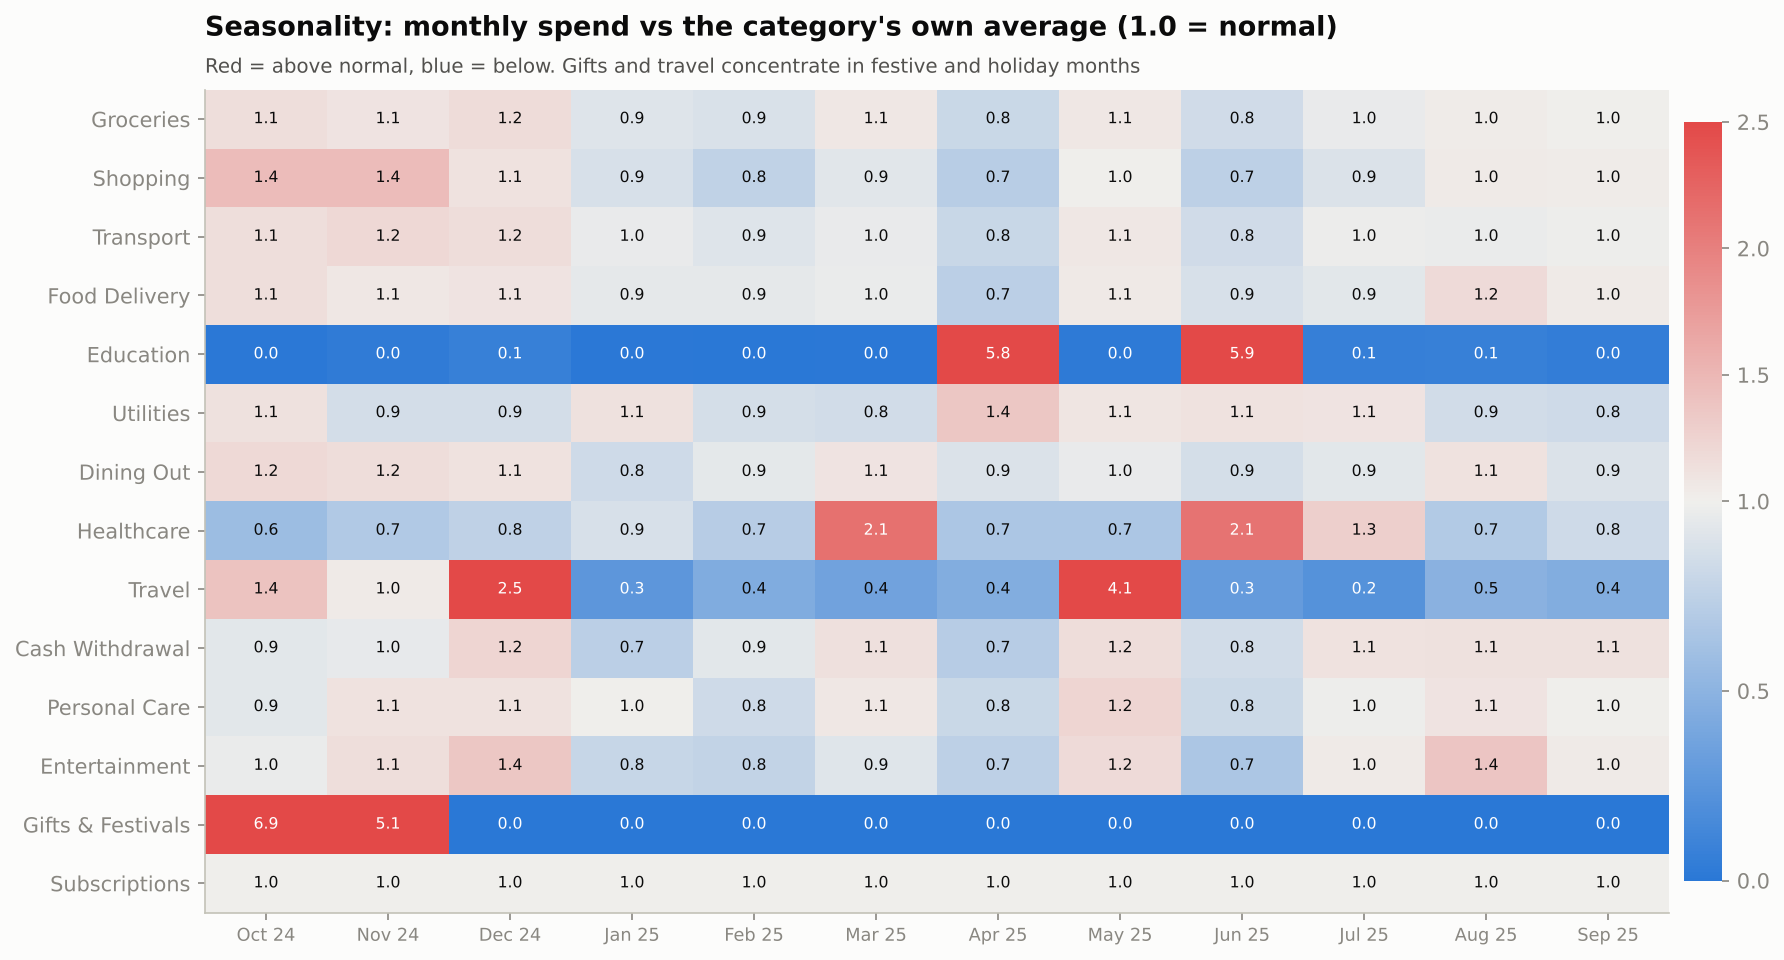

Oct-Nov festive months: +13% spend vs the other months' average


In [5]:
display(Image(ROOT / "reports/figures/03_category_seasonality_heatmap.png", width=950))
print(f"Oct-Nov festive months: {K['festive_uplift']:+.0%} spend vs the other months' average")

## 4. Savings & income stability by occupation

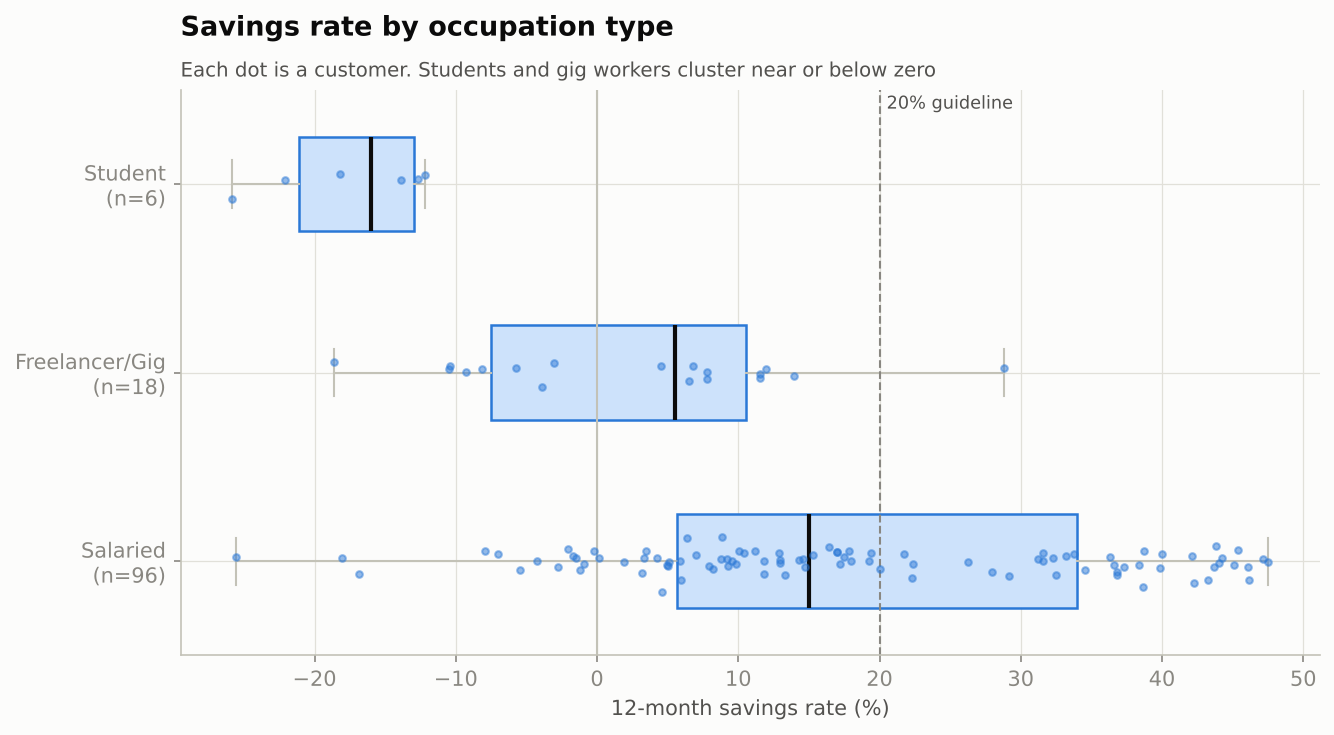

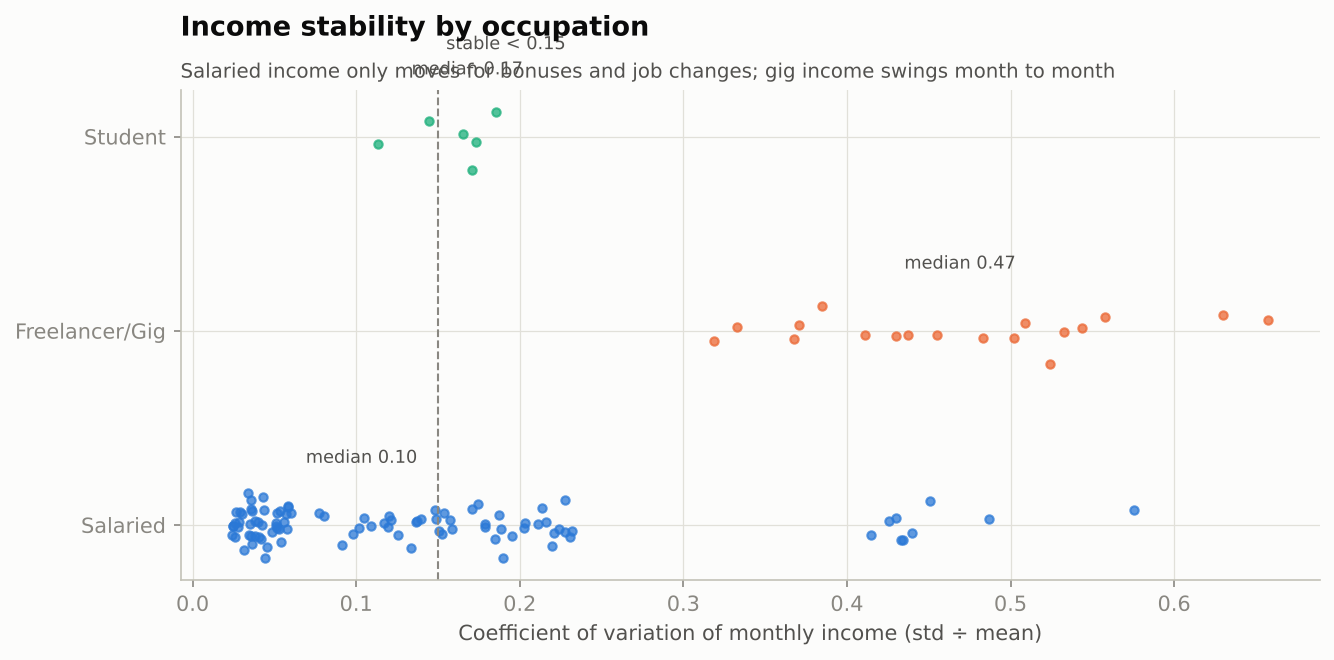

,median savings rate,median income CV
Freelancer/Gig,0.06,0.47
Salaried,0.15,0.10
Student,-0.16,0.17


In [6]:
display(Image(ROOT / "reports/figures/04_savings_rate_by_occupation.png", width=800))
display(Image(ROOT / "reports/figures/05_income_stability.png", width=800))
pd.DataFrame({"median savings rate": K["savings_rate_by_occupation"], "median income CV": K["median_income_cv_by_occupation"]})

## 5. Recurring expenses

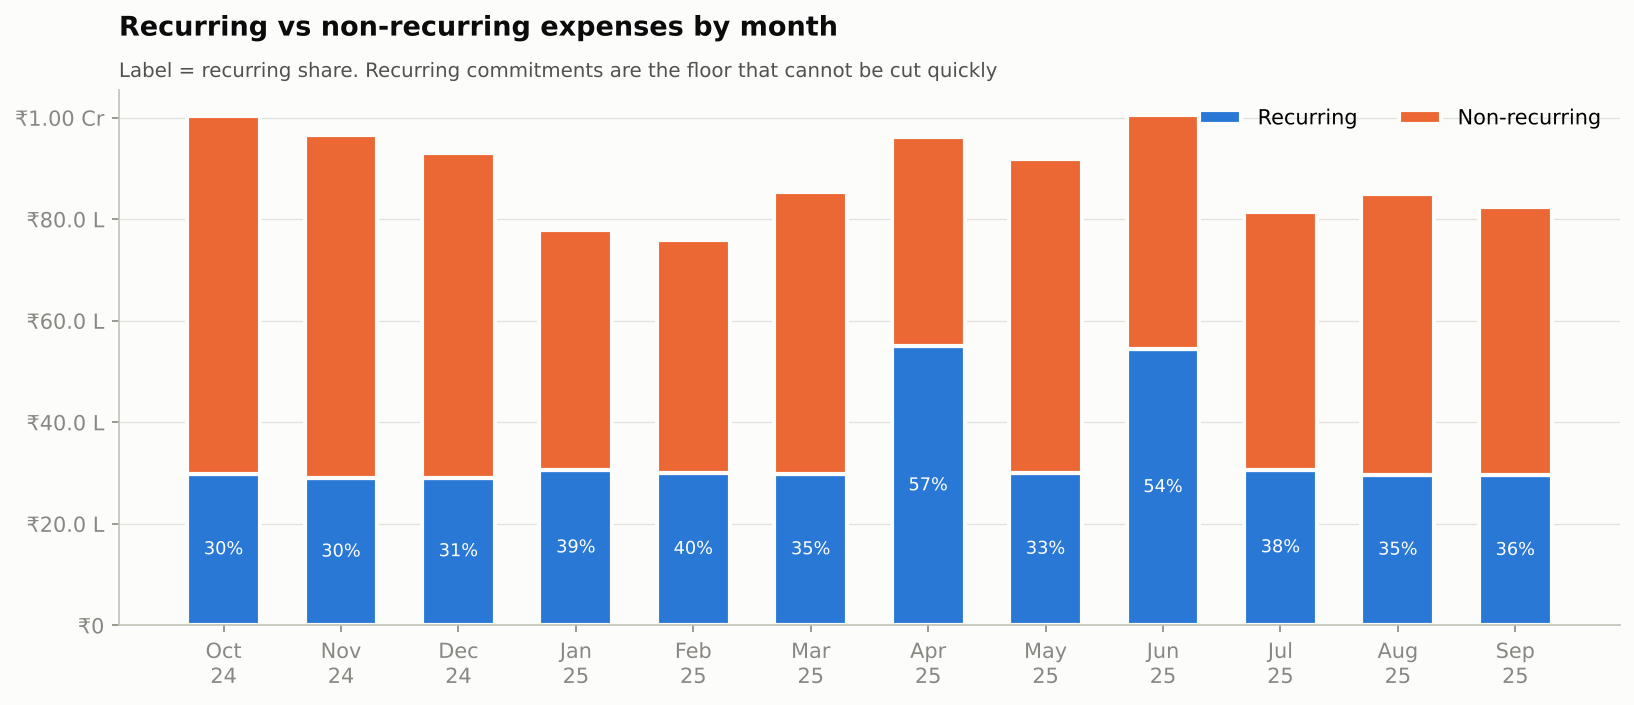

Recurring share of expenses: 38%; customers with obligations > 50% of income: 15%


In [7]:
display(Image(ROOT / "reports/figures/09_recurring_vs_variable.png", width=900))
print(f"Recurring share of expenses: {K['recurring_share_of_expenses']:.0%}; customers with obligations > 50% of income: {K['share_customers_foir_above_50']:.0%}")

## 6. Average transaction value

In [8]:
pd.read_csv(ROOT / "reports/eda_tables/avg_transaction_value_by_category.csv").round(0)

,category,mean,median,count
0,Loan EMI,"18,755.00","13,984.00",660
1,Housing,"17,227.00","13,800.00",936
2,Education,"32,731.00","8,970.00",151
3,Travel,"5,422.00","5,084.00",434
4,Shopping,"3,943.00","3,099.00",2628
5,Gifts & Festivals,"3,412.00","3,063.00",399
6,Groceries,"3,759.00","2,907.00",6355
7,Debt Repayment,"3,775.00","2,473.00",185
8,Cash Withdrawal,"2,056.00","1,800.00",1026
9,Dining Out,"2,017.00","1,654.00",1696


## 7. Weekend vs weekday

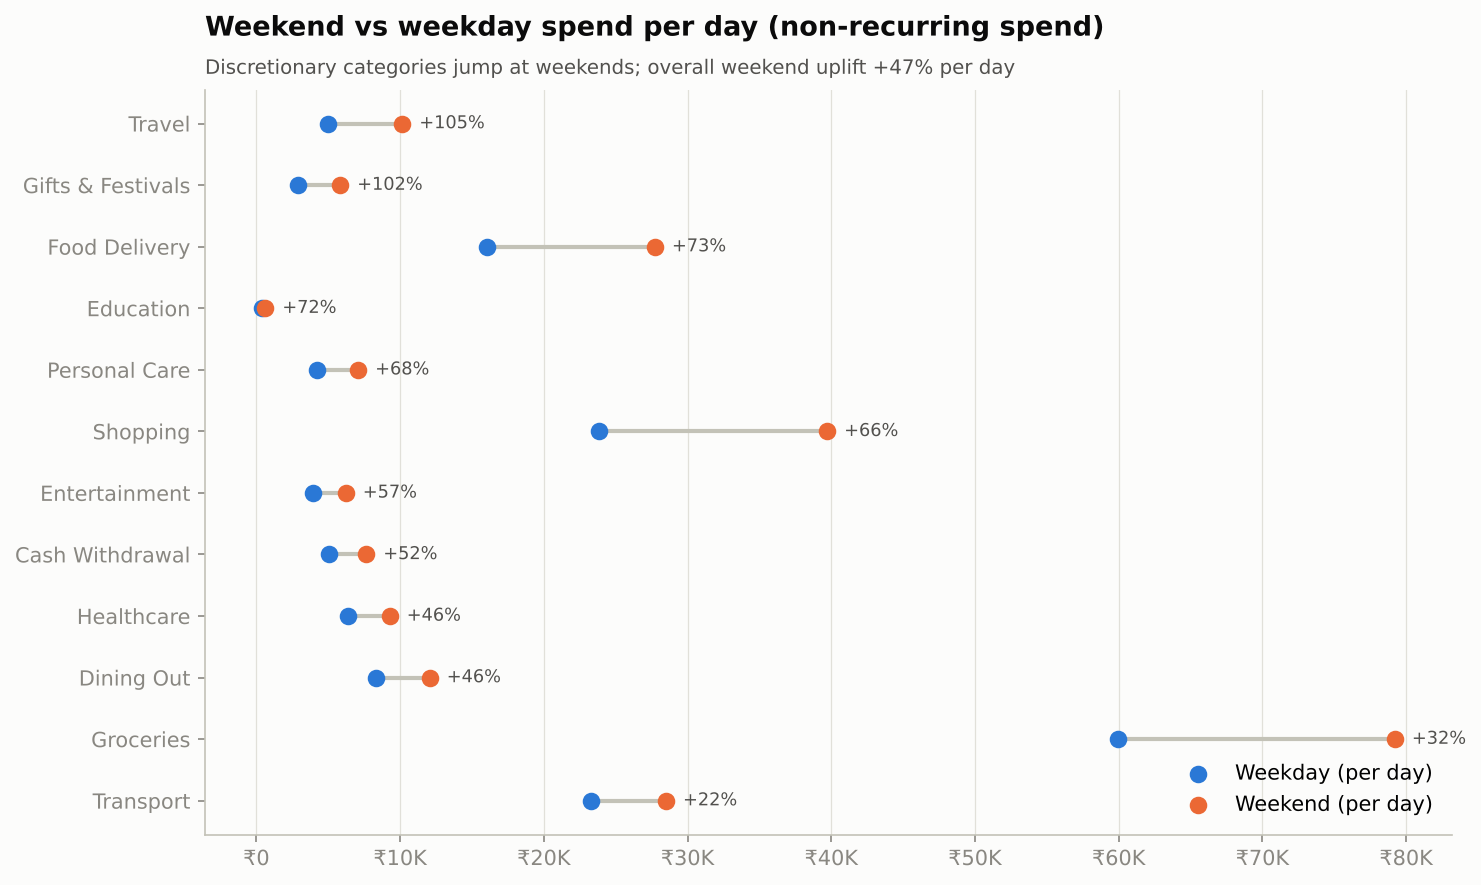

In [9]:
display(Image(ROOT / "reports/figures/06_weekend_vs_weekday.png", width=850))

## 8. Payment-method behaviour

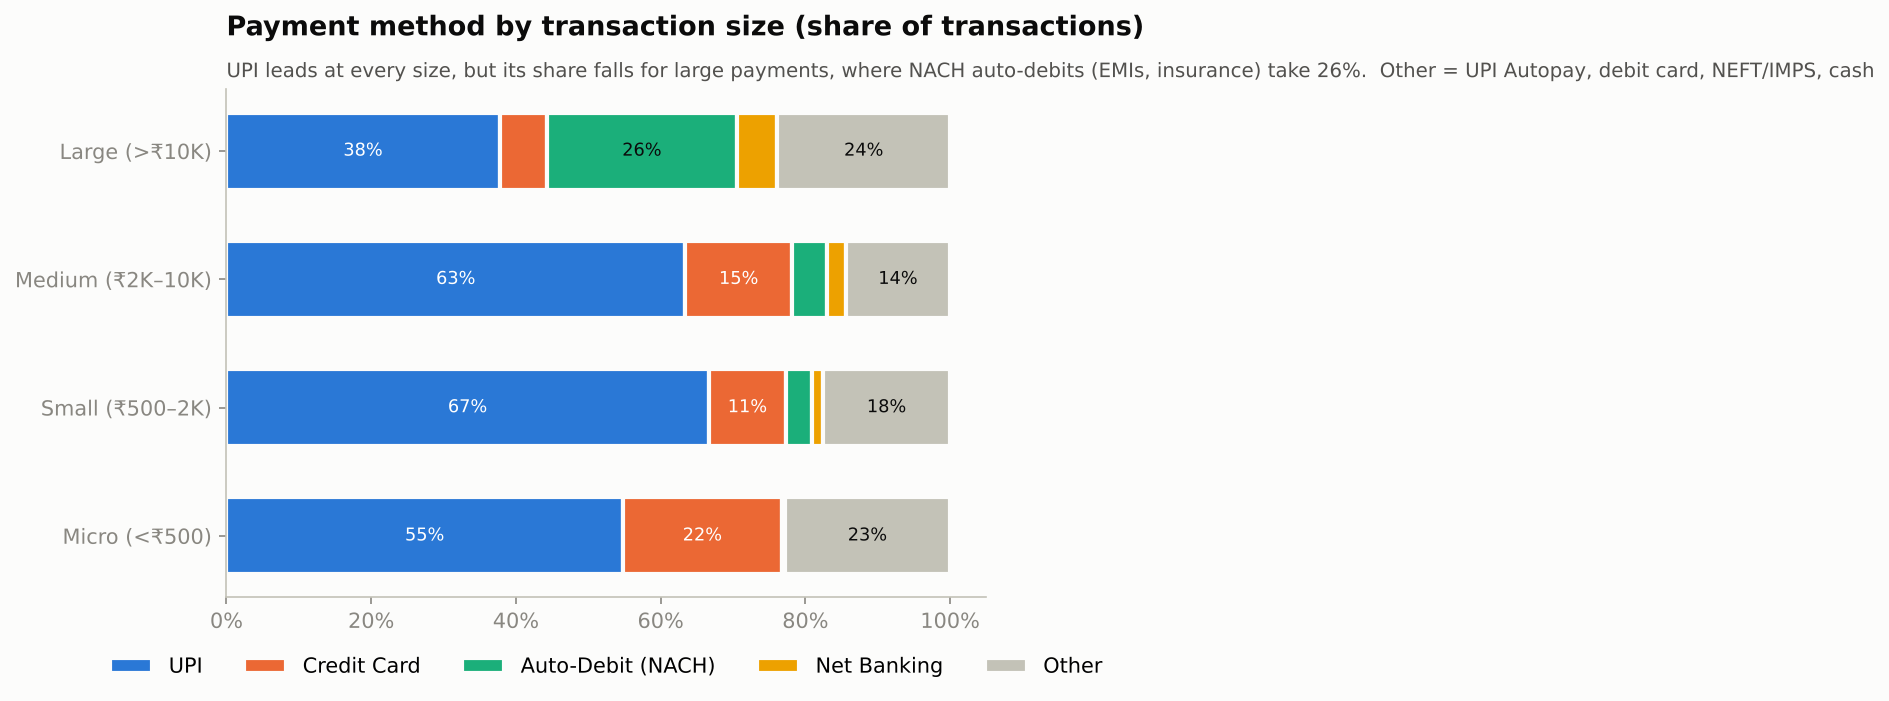

,size_band,UPI,Credit Card,Auto-Debit (NACH),Net Banking,Other
0,Micro (<₹500),0.55,0.22,0.00,0.00,0.23
1,Small (₹500–2K),0.67,0.11,0.04,0.02,0.18
2,Medium (₹2K–10K),0.63,0.15,0.05,0.03,0.14
3,Large (>₹10K),0.38,0.07,0.26,0.06,0.24


In [10]:
display(Image(ROOT / "reports/figures/07_payment_method_mix.png", width=850))
pd.read_csv(ROOT / "reports/eda_tables/payment_method_by_size_band.csv")

## 9. Merchant concentration

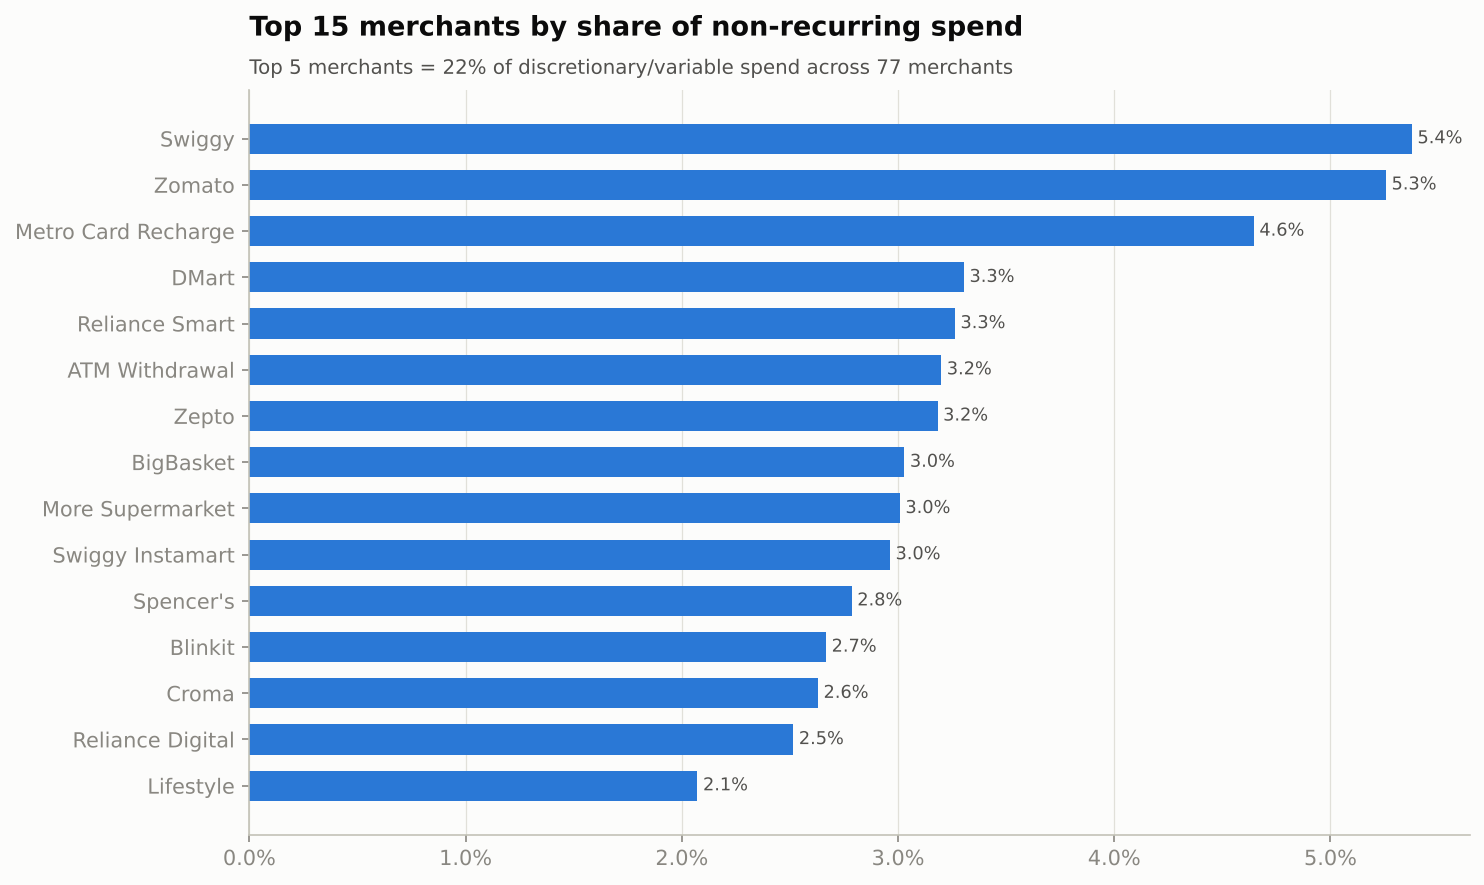

Top-5 merchants: 22% of variable spend; median customer's top-3 merchants: 25% of their spend


In [11]:
display(Image(ROOT / "reports/figures/08_merchant_concentration.png", width=850))
print(f"Top-5 merchants: {K['top5_merchant_share']:.0%} of variable spend; median customer's top-3 merchants: {K['median_customer_top3_merchant_share']:.0%} of their spend")